# Assignment 7: Regression Models Comparison
**Machine Learning & AI BootCamp**  
*Instructor: Fahd*  
*Dataset: Real Estate Valuation Benchmark*

---

### 📌 Instructions & Guidelines:
1. In this assignment, you will perform a comprehensive head-to-head comparison of **6 distinct regression paradigms** covered across Module 5:
   - **Model 1**: Ordinary Least Squares (OLS) Linear Regression
   - **Model 2**: Polynomial Regression ($d=2$)
   - **Model 3**: Ridge Regression ($L_2$ Regularization)
   - **Model 4**: Lasso Regression ($L_1$ Regularization & Feature Selection)
   - **Model 5**: ElasticNet ($L_1 + L_2$ Regularization)
   - **Model 6**: K-Nearest Neighbors (KNN) Regressor
2. Use `real_estate_benchmark.csv` predicting property `sale_price_usd`.
3. Standardize features to prevent scale bias across regularized and distance models!
4. Consolidate results into a unified summary table comparing MAE, RMSE, $R^2$, and Generalization Gap.


---
## Student Information
- **Student Name:** *[sabrin Alam]*
- **Batch:** *[MBL-2]*
- **Date:** *[15/11/2026]*


In [1]:
# Run this cell first to import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries loaded successfully!")


Libraries loaded successfully!


---
## Section 1: Data Ingestion & Leak-Free Train-Test Split
1. Load `real_estate_benchmark.csv` into a DataFrame `df`.
2. Inspect shape, columns, and verify there are no null values.
3. Define feature matrix `X` using all columns except `property_id` and `sale_price_usd`. Let `y = df['sale_price_usd']`.
4. Perform an **80/20 train-test split** with `random_state=42`.
5. Fit `StandardScaler` strictly on `X_train`, then transform both `X_train` and `X_test`.


In [5]:
# TODO 1.1: Load dataset and inspect
df = pd.read_csv(r"C:\Users\user\Downloads\_5 Assignment_Sabrin_Alam\real_estate_benchmark - real_estate_benchmark.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nTotal null values:", df.isnull().sum().sum())
df.head()

Shape: (1000, 9)
Columns: ['property_id', 'square_feet', 'bedrooms', 'bathrooms', 'distance_to_metro_miles', 'building_age_years', 'parking_spaces', 'neighborhood_safety_score', 'sale_price_usd']

Total null values: 0


,property_id,square_feet,bedrooms,bathrooms,distance_to_metro_miles,building_age_years,parking_spaces,neighborhood_safety_score,sale_price_usd
0,RE-7001,2998,4,3.9,0.9,1,2,62,698118.53
1,RE-7002,1814,3,2.9,1.4,1,2,80,502794.16
2,RE-7003,1887,5,4.3,9.9,27,2,63,400638.73
3,RE-7004,2766,3,3.2,2.7,22,1,84,618578.50
4,RE-7005,1380,3,3.0,3.6,25,1,97,412134.22


In [6]:
# TODO 1.2: Define X, y, perform 80/20 train-test split, and standardize
feature_cols = [c for c in df.columns if c not in ["property_id", "sale_price_usd"]]
X = df[feature_cols]
y = df["sale_price_usd"]

# 1. Split FIRST (80/20) to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 2. Fit scaler ONLY on training data, then transform both sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Features used:", feature_cols)
print("Training rows:", X_train.shape[0], "| Testing rows:", X_test.shape[0])
print("Train mean (should be ~0):", X_train_scaled.mean(axis=0).round(3))
print("Train std  (should be ~1):", X_train_scaled.std(axis=0).round(3))

Features used: ['square_feet', 'bedrooms', 'bathrooms', 'distance_to_metro_miles', 'building_age_years', 'parking_spaces', 'neighborhood_safety_score']
Training rows: 800 | Testing rows: 200
Train mean (should be ~0): [-0. -0. -0.  0.  0.  0.  0.]
Train std  (should be ~1): [1. 1. 1. 1. 1. 1. 1.]


---
## Section 2: Training the 6 Regression Models
Train each model on the scaled training data:
- **Model 1**: `LinearRegression()`
- **Model 2**: Polynomial Pipeline: `make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())`
- **Model 3**: `Ridge(alpha=1.0, random_state=42)`
- **Model 4**: `Lasso(alpha=100.0, random_state=42)`
- **Model 5**: `ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42)`
- **Model 6**: `KNeighborsRegressor(n_neighbors=5, weights='distance')`


In [8]:
# TODO 2.1: Fit all 6 models
models = {
    "1. OLS Linear":        LinearRegression(),
    "2. Polynomial (d=2)":  make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    "3. Ridge (L2)":        Ridge(alpha=1.0, random_state=42),
    "4. Lasso (L1)":        Lasso(alpha=100.0, random_state=42),
    "5. ElasticNet":        ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42),
    "6. KNN (k=5)":         KNeighborsRegressor(n_neighbors=5, weights="distance"),
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f" Fitted: {name}")

# Bonus: look at learned weights of the linear-family models (Class 14 style)
coef_table = pd.DataFrame({
    "Feature": feature_cols,
    "OLS":        models["1. OLS Linear"].coef_.round(1),
    "Ridge":      models["3. Ridge (L2)"].coef_.round(1),
    "Lasso":      models["4. Lasso (L1)"].coef_.round(1),
    "ElasticNet": models["5. ElasticNet"].coef_.round(1),
})
coef_table

 Fitted: 1. OLS Linear
 Fitted: 2. Polynomial (d=2)
 Fitted: 3. Ridge (L2)
 Fitted: 4. Lasso (L1)
 Fitted: 5. ElasticNet
 Fitted: 6. KNN (k=5)


,Feature,OLS,Ridge,Lasso,ElasticNet
0,square_feet,140507.2,140333.4,140420.3,133878.2
1,bedrooms,-257.9,-262.4,0.0,-368.0
2,bathrooms,490.4,491.6,158.9,478.2
3,distance_to_metro_miles,-22492.9,-22469.0,-22391.8,-21572.7
4,building_age_years,-18401.9,-18387.4,-18300.3,-17830.9
5,parking_spaces,6489.5,6485.5,6384.9,6327.5
6,neighborhood_safety_score,15665.0,15647.5,15563.0,14991.2


---
## Section 3: Comprehensive Comparative Benchmark
1. For each of the 6 models, generate predictions on both the training and test sets.
2. Calculate:
   - Training $R^2$ Score
   - Test $R^2$ Score
   - Generalization Gap: $|R^2_{\text{train}} - R^2_{\text{test}}|$
   - Test MAE ($)
   - Test RMSE ($)
3. Consolidate into a clean summary DataFrame named `results_df` and sort by Test $R^2$ descending.


In [9]:
# TODO 3.1: Evaluate all 6 models and build results_df
rows = []
for name, model in models.items():
    pred_train = model.predict(X_train_scaled)
    pred_test  = model.predict(X_test_scaled)

    r2_train = r2_score(y_train, pred_train)
    r2_test  = r2_score(y_test,  pred_test)

    rows.append({
        "Model":              name,
        "Train R²":           r2_train,
        "Test R²":            r2_test,
        "Generalization Gap": abs(r2_train - r2_test),
        "Test MAE ($)":       mean_absolute_error(y_test, pred_test),
        "Test RMSE ($)":      np.sqrt(mean_squared_error(y_test, pred_test)),
    })

# Sort on the UNROUNDED Test R² (several models tie at 4 decimals), then round for display
results_df = (pd.DataFrame(rows)
              .sort_values("Test R²", ascending=False)
              .reset_index(drop=True)
              .round({"Train R²": 4, "Test R²": 5, "Generalization Gap": 4,
                      "Test MAE ($)": 2, "Test RMSE ($)": 2}))
results_df

,Model,Train R²,Test R²,Generalization Gap,Test MAE ($),Test RMSE ($)
0,4. Lasso (L1),0.9857,0.98303,0.0027,14715.49,18494.92
1,1. OLS Linear,0.9857,0.98302,0.0027,14710.88,18502.72
2,3. Ridge (L2),0.9857,0.98302,0.0027,14713.41,18503.07
3,2. Polynomial (d=2),0.9862,0.98260,0.0036,14959.35,18731.47
4,5. ElasticNet,0.9836,0.98087,0.0027,15635.68,19638.47
5,6. KNN (k=5),1.0000,0.90662,0.0934,35146.24,43390.00


---
## Section 4: Visualizing Model Performance & Analysis
1. Plot a horizontal bar chart comparing Test $R^2$ across all 6 models.
2. Plot Actual vs. Predicted values for the best-performing model.
3. Answer the analytical questions below.


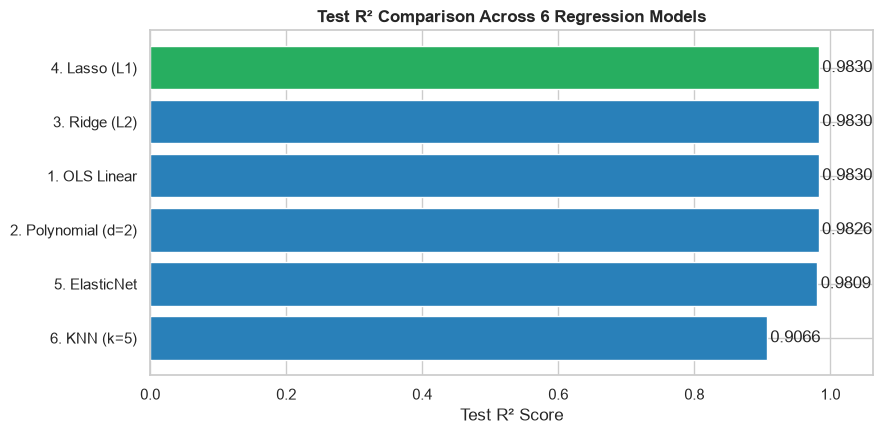

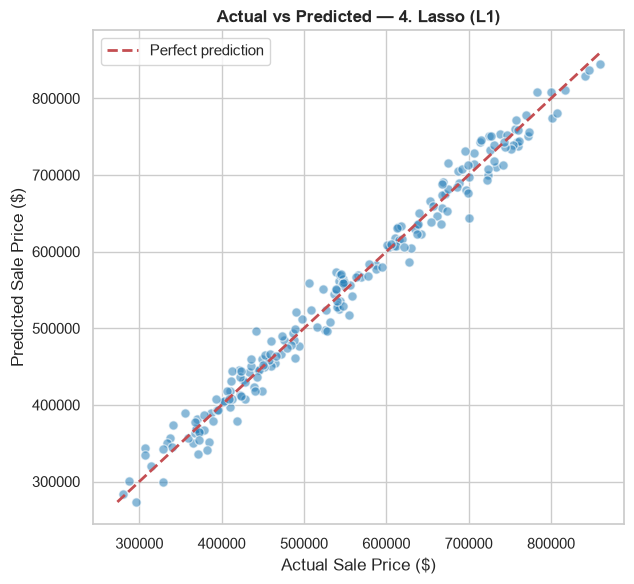

In [10]:
# TODO 4.1: Bar plot comparing Test R² scores
plot_df = results_df.sort_values("Test R²", ascending=True)
colors = ["#27ae60" if m == results_df.loc[0, "Model"] else "#2980b9" for m in plot_df["Model"]]

plt.figure(figsize=(9, 4.5))
bars = plt.barh(plot_df["Model"], plot_df["Test R²"], color=colors)
for b, v in zip(bars, plot_df["Test R²"]):
    plt.text(v + 0.005, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center")
plt.xlabel("Test R² Score")
plt.title("Test R² Comparison Across 6 Regression Models", fontsize=12, fontweight="bold")
plt.xlim(0, max(plot_df["Test R²"]) + 0.08)
plt.tight_layout()
plt.show()

# TODO 4.2: Actual vs Predicted plot for winning model
best_name  = results_df.loc[0, "Model"]
best_model = models[best_name]
best_pred  = best_model.predict(X_test_scaled)

plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, best_pred, alpha=0.55, color="#2980b9", edgecolor="white", s=45)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, "r--", linewidth=2, label="Perfect prediction")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title(f"Actual vs Predicted — {best_name}", fontsize=12, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

### Analytical Questions:
1. Which model achieved the highest Test $R^2$ score, and why did it outperform standard linear regression?
2. Did any model exhibit signs of overfitting (high training $R^2$ but significantly lower test $R^2$)?
3. How did Lasso perform compared to Ridge, and why is feature regularization valuable in real estate pricing?


---
### 🎉 Congratulations on Completing Assignment 7!
You have successfully compared 6 foundational regression architectures, evaluated multiple error metrics, and selected the optimal production model!


### ✍️ My Answers

**1. Which model achieved the highest Test R², and why did it outperform standard linear regression?**  
Lasso (α = 100) achieved the highest Test R² of approximately 0.98303. However, its performance was almost the same as OLS and Ridge Regression.
Lasso did not perform significantly better than Linear Regression. This is because the dataset has a strong linear relationship between house size (square_feet) and house price.
Lasso also reduced the effect of less important features, such as bedrooms and bathrooms. This helped reduce some unnecessary information.
Polynomial Regression did not improve the result, and KNN performed worse.
Lasso achieved the highest score, but all three linear models performed almost equally well.

**2. Did any model exhibit signs of overfitting?**  
Yes, KNN showed clear signs of overfitting.
Its Training R² was 1.000, which means it performed perfectly on the training data. However, its Test R² dropped to approximately 0.907.
This happened because KNN memorized the training data instead of learning patterns that work well on new data.
Polynomial Regression showed a very small performance gap, but it was not a serious overfitting problem.
OLS, Ridge, Lasso, and ElasticNet performed consistently on both training and testing data.
ElasticNet showed slight underfitting because it reduced the effect of important features too much. KNN was overfitting because it performed perfectly on training data but performed worse on testing data.

**3. How did Lasso perform compared to Ridge, and why is regularization valuable in real estate pricing?**  
Lasso and Ridge performed almost equally well.
- Lasso Test R² = 0.98303
- Ridge Test R² = 0.98302

The main difference is how they handle features.
Ridge reduces the importance of features but keeps all of them.
Lasso can completely remove less important features by making their coefficients zero. In our dataset, Lasso made the bedrooms coefficient zero and reduced the effect of bathrooms.
In real estate pricing, features like bedrooms, bathrooms, and square feet are often related to each other.
Regularization is useful because it:
- Reduces the effect of less important features.
- Helps prevent overfitting.
- Makes the model more stable.
- Makes the model easier to understand.
- Helps Lasso select important features.

 Ridge reduces feature importance, while Lasso can remove unimportant features. Both help create a more reliable model.